# T05 - Simulación Multiactivo

---
Nombre: **Alan Jesús Hernández Soto**  
Carrera: **Ingeniería Financiera**  
Materia: **Simulación de Procesos Financieros**  
Tipo de trabajo: **Tarea**

---

La tarea consiste en revisar la "independencia" supuesta de los activos de sectores distintos, y ver la diferencia entre los casos "independientes" y "correlacionados".

## Portafolios considerando correlación
1.- Repite el ejercicio A) pero ahora considera que sí hay correlación entre los factores. Utiliza los mismos 3 esquemas de inversión vistos en clase y compara.

### Preparación de los datos

Se utilizan los activos NVDA, BIMBOA.MX, CEMEXCPO.MX y AZN.
Para comparar ambos supuestos, se calculan los rendimientos logarítmicos
y su matriz de covarianza.

Los precios de NVDA y AZN se convierten a pesos mexicanos. Se utiliza
un tipo de cambio esperado constante para todos los escenarios, como
en el ejercicio realizado en clase.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

capital = 100000
T = 1
sims = 10000

tickers = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN']

prices = yf.download(tickers, start='2023-11-02', auto_adjust=True)['Close']

forex = yf.download('USDMXN=X', start='2023-11-02', end='2026-11-12', auto_adjust=True)['Close']

prices = prices.loc[:, tickers]

display(prices.tail())
display(forex.tail())

[*********************100%***********************]  4 of 4 completed
[*********************100%***********************]  1 of 1 completed


Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN
Date,,,,
2026-11-05,181.600006,69.599998,20.200001,186.850006
2026-11-06,186.639999,70.989998,20.150000,186.429993
2026-11-09,178.669998,68.500000,20.639999,189.389999
2026-11-10,168.889999,70.099998,20.150000,186.759995
2026-11-11,173.729996,71.309998,19.920000,185.479996


Ticker,USDMXN=X
Date,
2026-11-05,18.607700
2026-11-06,18.780880
2026-11-09,18.637449
2026-11-10,18.533381
2026-11-11,18.599199


In [2]:
def final_price(S0, mean, std, T, sims):
    return S0 * np.exp(mean * T + std * np.sqrt(T) * np.random.normal(size=sims))

In [ ]:
fecha = prices.dropna().index[-1]
prices = prices.loc[:fecha].dropna()
forex = forex.loc[:fecha].dropna()

lg_rets = np.log(prices / prices.shift(1)).dropna()
forex_returns = np.log(forex / forex.shift(1)).dropna()

S0_forex = forex.iloc[-1]
mean_forex = forex_returns.mean() * 252
std_forex = forex_returns.std() * np.sqrt(252)

T = 1

st_forex = S0_forex * np.exp(mean_forex * T + 0.5 * std_forex**2 * T)

print(f'Tipo de cambio inicial: {S0_forex:.2f} MXN/USD')
print(f'Tipo de cambio esperado: {st_forex:.2f} MXN/USD')

display(lg_rets.corr())

Tipo de cambio inicial: 18.60 MXN/USD
Tipo de cambio esperado: 18.99 MXN/USD


Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN
Ticker,,,,
NVDA,1.000000,0.074948,0.218909,0.017644
BIMBOA.MX,0.074948,1.000000,0.186046,0.096202
CEMEXCPO.MX,0.218909,0.186046,1.000000,0.100768
AZN,0.017644,0.096202,0.100768,1.000000


### Simulación independiente y correlacionada

Se generan 10,000 escenarios para un horizonte de un año. En el primer
caso, los factores aleatorios de los activos son independientes. En el
segundo, se utiliza la descomposición de Cholesky de la matriz de
covarianza anualizada para incorporar la relación histórica entre ellos.

In [10]:
np.random.seed(12)

n_act = len(tickers)
cov = lg_rets.cov() * 252
mean = lg_rets.mean() * 252
std = lg_rets.std() * np.sqrt(252)

L = np.linalg.cholesky(cov)

E = np.random.normal(0, 1, size=(n_act, sims))

Z_ind = E.T
Z_corr = (L @ E).T

ST_ind = np.zeros(shape=(sims, n_act))
ST_corr = np.zeros(shape=(sims, n_act))

cont = 0
for ticker in tickers:
    S0 = prices[ticker].iloc[-1]
    mu = mean[ticker]
    vol = std[ticker]
    ST_ind[:, cont] = S0 * np.exp( mu * T + vol * np.sqrt(T) * Z_ind[:, cont] )
    ST_corr[:, cont] = S0 * np.exp( mu * T + np.sqrt(T) * Z_corr[:, cont] )
    if ticker in ['NVDA', 'AZN']:
        ST_ind[:, cont] = ST_ind[:, cont] * st_forex
        ST_corr[:, cont] = ST_corr[:, cont] * st_forex

    cont += 1

### Carteras de inversión

Se comparan tres portafolios con un capital inicial de 100,000 MXN:

1. Inversión total en NVDA.
2. Portafolio equiponderado.
3. Portafolio con pesos crecientes de 10 %, 20 %, 30 % y 40 %.

Los pesos siguen el orden NVDA, BIMBOA.MX, CEMEXCPO.MX y AZN.
Se compran acciones enteras y se conserva el efectivo restante.

In [11]:
pesos = [ np.array([1, 0, 0, 0]), np.array([0.25, 0.25, 0.25, 0.25]), np.array([0.1, 0.2, 0.3, 0.4]) ]
S0 = prices.loc[:, tickers].iloc[-1]
S0.loc[['NVDA', 'AZN']] = S0.loc[['NVDA', 'AZN']] * S0_forex

port_ind = []
port_corr = []

for w in pesos:
    cap = w * capital
    N0 = np.floor(cap / S0)
    cash = capital - np.sum(N0 * S0)

    vt_ind = np.sum(ST_ind * N0.values, axis=1) + cash
    vt_corr = np.sum(ST_corr * N0.values, axis=1) + cash

    port_ind.append(vt_ind)
    port_corr.append(vt_corr)

### Comparación de distribuciones
Distribución de casos 1, 2, y 3 comparando independiente vs correlacionado.

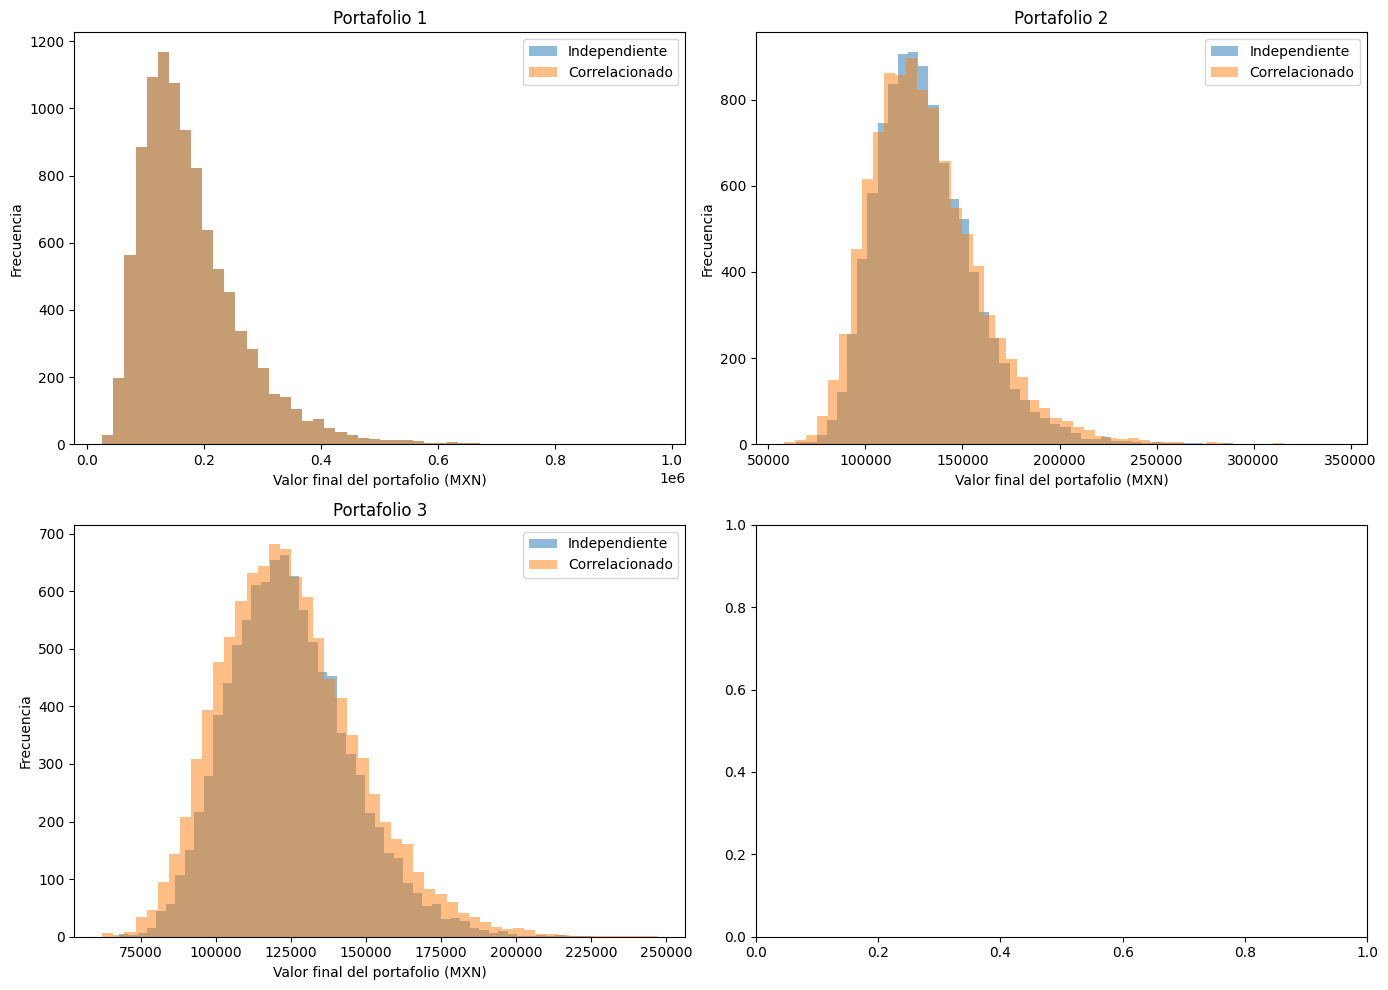

,Caso,Supuesto,Valor promedio,Desviación estándar,Percentil 5
0,1,Independiente,178591.87,88778.45,75402.44
1,1,Correlacionado,178591.87,88778.45,75402.44
2,2,Independiente,131144.24,25573.37,96213.75
3,2,Correlacionado,131109.57,28787.24,92127.61
4,3,Independiente,124869.05,20326.20,94844.11
5,3,Correlacionado,124830.47,23269.47,91106.94


In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

for i in range(3):
    grafica = ax.flat[i]

    grafica.hist(port_ind[i], bins=50, alpha=0.5, label='Independiente')
    grafica.hist(port_corr[i], bins=50, alpha=0.5, label='Correlacionado')
    grafica.set_title(f'Portafolio {i + 1}')
    grafica.set_xlabel('Valor final del portafolio (MXN)')
    grafica.set_ylabel('Frecuencia')
    grafica.legend()

plt.tight_layout()
plt.show()

resultados_A = []

for i in range(3):
    for nombre, valores in [('Independiente', port_ind[i]), ('Correlacionado', port_corr[i])]:
        resultados_A.append({
            'Caso': i + 1,
            'Ejercicio': nombre,
            'Valor promedio': np.mean(valores),
            'Desviación estándar': np.std(valores),
            'Percentil 5': np.percentile(valores, 5)
        })

resultados_A = pd.DataFrame(resultados_A)
display(resultados_A.round(2))

## Esquema de Inversión
2.- Aplica un esquema de inversión con 100k MXN en el ejercicio B); haz una simulación con los activos independientes y otra con ellos correlacionados. Utiliza los siguientes esquemas de inversión (considerando [AAPL, MSFT, NVDA]:

[1, 0, 0]
[0.33, 0.33, 0.34]
[0.2, 0.2, 0.6]
Realiza las mismas gráficas donde compares independiente vs correlacionado.
 

¿Qué observas? Utiliza markdown para explicar lo que ves en cada paso.

### Simulación de AAPL, MSFT y NVDA
Como los tres activos cotizan en dólares, sus precios iniciales y finales se convierten a pesos mexicanos con los tipos de cambio utilizados anteriormente.

In [20]:
tickers_B = ['AAPL', 'MSFT', 'NVDA']
prices_B = yf.download(tickers_B, start='2023-11-02', end='2026-11-12', auto_adjust=True)['Close']

prices_B = prices_B.dropna()
lg_rets_B = np.log(prices_B / prices_B.shift(1)).dropna()

display(lg_rets_B.corr())

[*********************100%***********************]  3 of 3 completed


Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,1.000000,0.343476,0.275020
MSFT,0.343476,1.000000,0.411339
NVDA,0.275020,0.411339,1.000000


### Factores independientes y correlacionados

Se calcula la matriz de covarianza anualizada y se aplica Cholesky. Los factores resultantes se utilizan para obtener los precios finales de los tres activos en cada escenario.

In [22]:
np.random.seed(12)

n_act_B = len(tickers_B)
cov_B = lg_rets_B.cov() * 252
mean_B = lg_rets_B.mean() * 252
std_B = lg_rets_B.std() * np.sqrt(252)

Lb = np.linalg.cholesky(cov_B)
Eb = np.random.normal(0, 1, size=(n_act_B, sims))

Zbind = Eb.T
Zbcorr = (Lb @ Eb).T

STb_ind = np.zeros(shape=(sims, n_act_B))
STb_corr = np.zeros(shape=(sims, n_act_B))

cont = 0
for ticker in tickers_B:
    S0 = prices_B[ticker].iloc[-1]
    mu = mean_B[ticker]
    vol = std_B[ticker]
    STb_ind[:, cont] = S0 * np.exp( mu * T + vol * np.sqrt(T) * Zbind[:, cont])
    STb_corr[:, cont] = S0 * np.exp( mu * T + np.sqrt(T) * Zbcorr[:, cont])
    STb_ind[:, cont] = STb_ind[:, cont] * st_forex
    STb_corr[:, cont] = STb_corr[:, cont] * st_forex

    cont += 1

### Pesos
Los pesos se asignan en el orden AAPL, MSFT y NVDA:

1. 100 %, 0 % y 0 %.
2. 33 %, 33 % y 34 %.
3. 20 %, 20 % y 60 %.

Se compran acciones enteras y se conserva el efectivo restante.

In [23]:
pesos_B = [ np.array([1, 0, 0]), np.array([0.33, 0.33, 0.34]), np.array([0.2, 0.2, 0.6]) ]
S0b = prices_B.loc[:, tickers_B].iloc[-1] * S0_forex

port_B_ind = []
port_B_corr = []

for w in pesos_B:
    cap = w * capital
    N0 = np.floor(cap / S0b)
    cash = capital - np.sum(N0 * S0b)

    vt_ind = np.sum(STb_ind * N0.values, axis=1) + cash
    vt_corr = np.sum(STb_corr * N0.values, axis=1) + cash

    port_B_ind.append(vt_ind)
    port_B_corr.append(vt_corr)

### Comparación de distribuciones

Se comparan los valores finales de cada esquema bajo los dos supuestos. La desviación estándar permite observar la dispersión de los resultados, mientras que el percentil 5 representa un valor que solo es superado hacia abajo en el 5 % de los escenarios simulados.

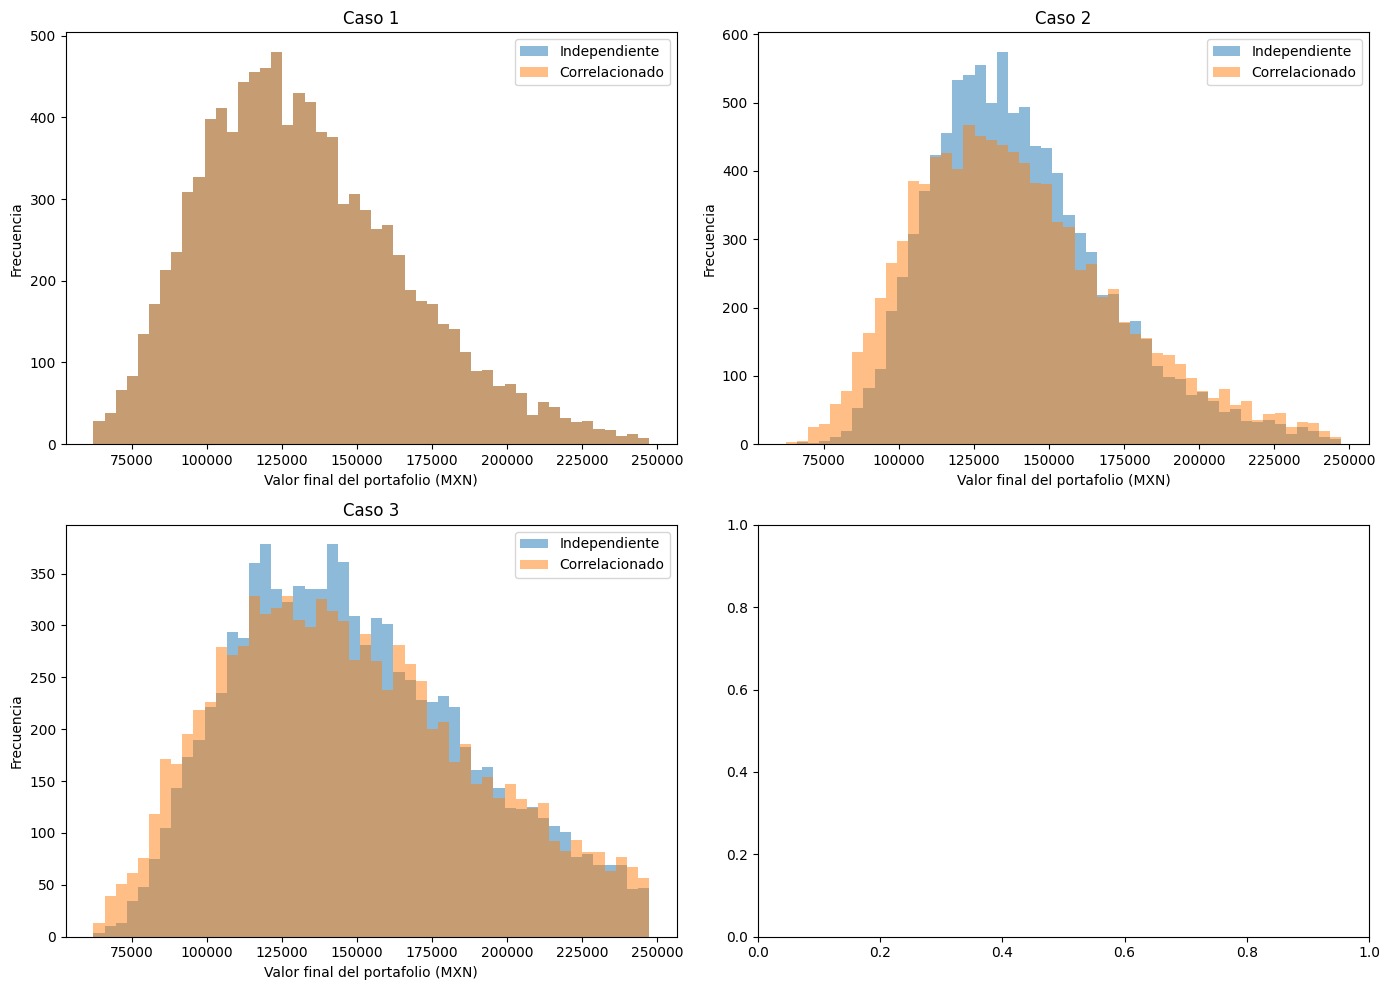

,Caso,Supuesto,Valor promedio,Desviación estándar,Percentil 5
0,1,Independiente,133194.79,36068.98,83569.14
1,1,Correlacionado,133194.79,36068.98,83569.14
2,2,Independiente,141223.45,31307.57,99469.38
3,2,Correlacionado,141098.25,37481.67,91812.91
4,3,Independiente,157700.67,51808.48,93398.65
5,3,Correlacionado,157529.97,56376.86,87097.30


In [24]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

for i in range(3):
    grafica = ax.flat[i]

    grafica.hist(port_B_ind[i], bins=limites, alpha=0.5, label='Independiente')
    grafica.hist(port_B_corr[i], bins=limites, alpha=0.5, label='Correlacionado')
    grafica.set_title(f'Caso {i + 1}')
    grafica.set_xlabel('Valor final del portafolio (MXN)')
    grafica.set_ylabel('Frecuencia')
    grafica.legend()
plt.tight_layout()
plt.show()

resultados_B = []

for i in range(3):
    for nombre, valores in [ ('Independiente', port_B_ind[i]), ('Correlacionado', port_B_corr[i])]:
        resultados_B.append({
            'Caso': i + 1,
            'Supuesto': nombre,
            'Valor promedio': np.mean(valores),
            'Desviación estándar': np.std(valores),
            'Percentil 5': np.percentile(valores, 5)
        })

resultados_B = pd.DataFrame(resultados_B)
display(resultados_B.round(2))

## Conclusión

En los casos que invierten en un solo activo, la distribución independiente coincide con la correlacionada. Esto ocurre porque la correlación entre activos no afecta a un portafolio que solo contiene un activo, bajo el supuesto de tipo de cambio constante utilizado. En los portafolios con varios activos, la correlación modifica la dispersión del valor final. 

Al comparar las desviaciones estándar y los percentiles 5 de las tablas, se observa que: 
- En el ejercicio A, los portafolios correlacionados tenían poquita mas dispersión en los datos, es decir la gráfica era mas ancha que los independientes. 
- En el ejercicio B, igual que en el A los portafolios correlacionados tienen mas dispersión, se podría decir que las carteras independientes tienen mayor kurtosis mas es necesario una prueba estadística para esto.